Device: cuda
Jumlah kelas: 81
Jumlah kata unik: 11045 | contoh: ['notebook', 'IPython:', 'containers,', 'capability', 'h(elp)', '3141.', ':math:s', '"magic']
Jumlah font: 28
Font dipakai: ['DejaVuSans-Bold.ttf', 'DejaVuSans-BoldOblique.ttf', 'DejaVuSans-Oblique.ttf', 'DejaVuSans.ttf', 'DejaVuSansMono-Bold.ttf', 'DejaVuSansMono-Oblique.ttf', 'DejaVuSansMono.ttf', 'DejaVuSerif-Bold.ttf', 'DejaVuSerif-Italic.ttf', 'DejaVuSerif.ttf', 'STIXGeneral.ttf', 'STIXGeneralBol.ttf', 'cmb10.ttf', 'cmr10.ttf', 'cmss10.ttf', 'cmtt10.ttf', 'LiberationMono-Bold.ttf', 'LiberationMono-Italic.ttf', 'LiberationMono-Regular.ttf', 'LiberationSans-Bold.ttf', 'LiberationSans-BoldItalic.ttf', 'LiberationSans-Italic.ttf', 'LiberationSans-Regular.ttf', 'LiberationSerif-Bold.ttf', 'LiberationSerif-Regular.ttf', 'NotoMono-Regular.ttf', 'NotoSansMono-Bold.ttf', 'NotoSansMono-Regular.ttf']


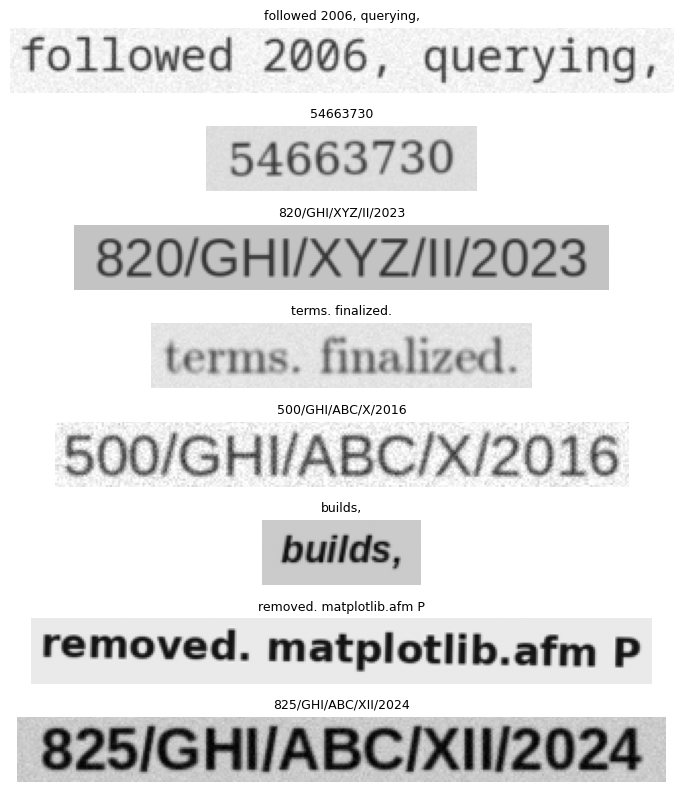

Parameter: 8.222225 juta


/tmp/ipykernel_252/1978521775.py:312: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(optimizer); scaler.update(); scheduler.step()


Epoch 01/30 | loss 4.3309 | CER 94.91% | WER 100.00% | exact 0.0% | 96s
   -> model terbaik disimpan
Epoch 02/30 | loss 0.7250 | CER 1.14% | WER 7.70% | exact 88.1% | 95s
   -> model terbaik disimpan
Epoch 03/30 | loss 0.0436 | CER 1.43% | WER 8.99% | exact 85.8% | 94s
Epoch 04/30 | loss 0.0330 | CER 2.07% | WER 19.26% | exact 77.3% | 94s
Epoch 05/30 | loss 0.0280 | CER 0.52% | WER 3.59% | exact 93.5% | 93s
   -> model terbaik disimpan
Epoch 06/30 | loss 0.0156 | CER 0.35% | WER 2.39% | exact 95.7% | 93s
   -> model terbaik disimpan
Epoch 07/30 | loss 0.0124 | CER 0.18% | WER 1.32% | exact 97.9% | 93s
   -> model terbaik disimpan
Epoch 08/30 | loss 0.0161 | CER 0.44% | WER 3.01% | exact 94.7% | 93s
Epoch 09/30 | loss 0.0110 | CER 0.26% | WER 1.88% | exact 96.8% | 93s
Epoch 10/30 | loss 0.0108 | CER 0.61% | WER 4.35% | exact 93.5% | 93s
Epoch 11/30 | loss 0.0105 | CER 0.45% | WER 3.84% | exact 94.5% | 93s
Epoch 12/30 | loss 0.0104 | CER 0.16% | WER 1.30% | exact 97.9% | 93s
   -> model 

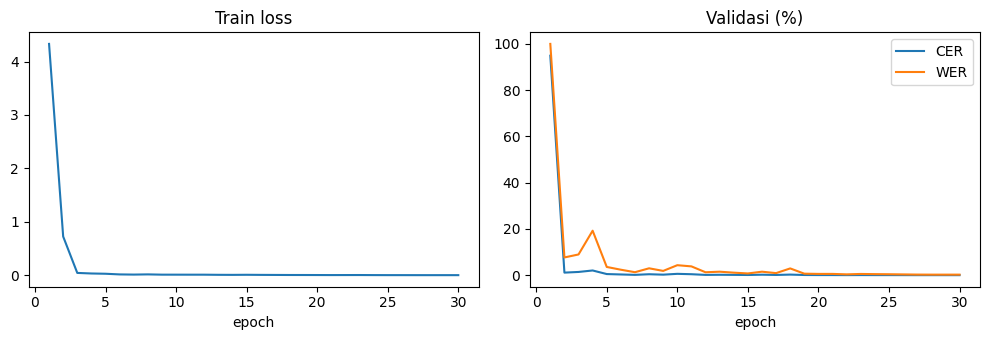

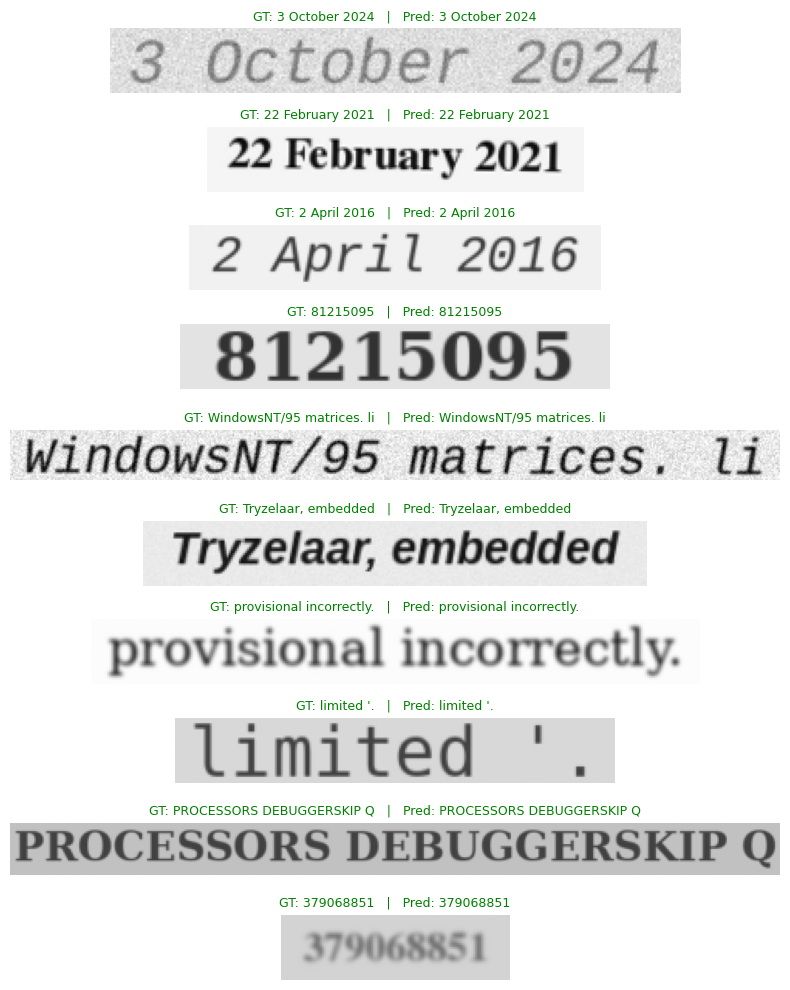

In [1]:
# ============================================================
# CELL: CRNN OCR (Recognition) - Versi Bahasa Inggris
# ============================================================

import os, sys, random, glob, string, time
import numpy as np
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image, ImageDraw, ImageFont, ImageFilter
import matplotlib
import matplotlib.pyplot as plt

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

# ---------- KONFIGURASI ----------
IMG_H = 32            # tinggi gambar (tetap)
MAX_LEN = 25          # maksimal karakter per baris
MAX_W = 512           # lebar maksimal gambar
BATCH_SIZE = 128
EPOCHS = 30
TRAIN_SIZE = 50000    # jumlah sampel per epoch (digenerate on-the-fly)
VAL_SIZE = 2000
LR = 1e-3
NUM_WORKERS = 4
OUT_DIR = "/kaggle/working"

# Charset: DIBUAT LENGKAP dari awal (termasuk "/" dan tanda baca surat)
# supaya nanti bisa fine-tune ke bahasa Indonesia tanpa ganti layer output.
CHARS = string.ascii_letters + string.digits + ".,:;-/()'\"&%#@!?+ "
BLANK = 0
char2idx = {c: i + 1 for i, c in enumerate(CHARS)}
idx2char = {i + 1: c for i, c in enumerate(CHARS)}
NUM_CLASSES = len(CHARS) + 1   # +1 untuk blank CTC
print("Jumlah kelas:", NUM_CLASSES)

# ============================================================
# CELL: 1. Sumber teks & font
# ============================================================

def build_corpus():
    words = set()
    for mod in list(sys.modules.values()):
        doc = getattr(mod, "__doc__", None)
        if isinstance(doc, str):
            for w in doc.split():
                w = "".join(c for c in w if c in CHARS)
                if 1 <= len(w) <= 14:
                    words.add(w)
    return sorted(words)

WORDS = build_corpus()
if len(WORDS) < 500:  # cadangan kalau corpus terlalu sedikit
    WORDS += ["".join(random.choices(string.ascii_lowercase, k=random.randint(3, 9))) for _ in range(2000)]
print("Jumlah kata unik:", len(WORDS), "| contoh:", random.sample(WORDS, 8))

REF_FONT = ImageFont.truetype(
    os.path.join(os.path.dirname(matplotlib.__file__), "mpl-data/fonts/ttf/DejaVuSans.ttf"), 40)
ALNUM = string.ascii_letters + string.digits

def norm_glyph(f, ch):
    # gambar 1 karakter, potong sesuai bentuknya, kecilkan jadi 24x24
    im = Image.new("L", (80, 80), 0)
    ImageDraw.Draw(im).text((10, 5), ch, font=f, fill=255)
    bb = im.getbbox()
    if bb is None:
        return None
    return np.asarray(im.crop(bb).resize((24, 24), Image.BILINEAR), dtype=np.float32) / 255

REF_GLYPHS = {c: norm_glyph(REF_FONT, c) for c in ALNUM}

def font_is_good(path, min_sim=0.45):
    try:
        f = ImageFont.truetype(path, 40)
    except Exception:
        return False

    def glyph(ch):
        im = Image.new("L", (64, 64), 0)
        ImageDraw.Draw(im).text((8, 4), ch, font=f, fill=255)
        return im.tobytes()

    # Cek 1: tidak ada karakter yang kosong / berupa kotak, dan bentuknya beda-beda
    blank = Image.new("L", (64, 64), 0).tobytes()
    notdef = glyph("\uFFFF")
    masks = {}
    for ch in CHARS:
        if ch == " ":
            continue
        g = glyph(ch)
        if g == blank or g == notdef:
            return False
        masks[ch] = g
    if len(set(masks.values())) < len(masks) - 3:
        return False

    # Cek 2: huruf & angka harus MIRIP bentuk huruf biasa (membuang font simbol/matematika,
    # misalnya huruf yang tergambar sebagai akar kuadrat atau kurung besar)
    sims = []
    for c, ref in REF_GLYPHS.items():
        g = norm_glyph(f, c)
        if g is None:
            return False
        a, b = g - g.mean(), ref - ref.mean()
        sims.append((a * b).sum() / (np.sqrt((a * a).sum() * (b * b).sum()) + 1e-8))
    return float(np.mean(sims)) >= min_sim

def find_fonts():
    paths = glob.glob("/usr/share/fonts/**/*.ttf", recursive=True)
    paths += glob.glob(os.path.join(os.path.dirname(matplotlib.__file__), "mpl-data/fonts/ttf/*.ttf"))
    return [p for p in sorted(set(paths)) if font_is_good(p)]

FONTS = find_fonts()
print("Jumlah font:", len(FONTS))
assert len(FONTS) > 0, "Tidak ada font ditemukan"
print("Font dipakai:", [os.path.basename(p) for p in FONTS])

# ============================================================
# CELL: 2. Generator gambar baris teks + augmentasi
# ============================================================

MONTHS = ["January", "February", "March", "April", "May", "June", "July",
          "August", "September", "October", "November", "December"]
ROMAN = ["I", "II", "III", "IV", "V", "VI", "VII", "VIII", "IX", "X", "XI", "XII"]

def random_text():
    r = random.random()
    if r < 0.50:      # kalimat/kata biasa
        t = " ".join(random.choice(WORDS) for _ in range(random.randint(1, 4)))
    elif r < 0.62:    # angka
        t = "".join(random.choices(string.digits, k=random.randint(2, 12)))
    elif r < 0.74:    # pola nomor dokumen
        t = "%d/%s/%s/%s/%d" % (random.randint(1, 999),
                                random.choice(["ABC", "XYZ", "DEF", "GHI"]),
                                random.choice(["ABC", "XYZ"]),
                                random.choice(ROMAN), random.randint(2015, 2026))
    elif r < 0.84:    # tanggal
        t = "%d %s %d" % (random.randint(1, 31), random.choice(MONTHS), random.randint(2015, 2026))
    elif r < 0.92:    # HURUF BESAR
        t = " ".join(random.choice(WORDS) for _ in range(random.randint(1, 3))).upper()
    else:             # Kapital Di Awal Kata
        t = " ".join(random.choice(WORDS).capitalize() for _ in range(random.randint(1, 4)))
    t = t[:MAX_LEN].strip()
    return t if t else "A"

def render_text(text):
    font = ImageFont.truetype(random.choice(FONTS), random.randint(24, 44))
    l, t, r, b = font.getbbox(text)
    padx, pady = random.randint(4, 16), random.randint(4, 12)
    w, h = max(r - l, 1) + 2 * padx, max(b - t, 1) + 2 * pady
    bg, fg = random.randint(190, 255), random.randint(0, 90)

    img = Image.new("L", (w, h), bg)
    ImageDraw.Draw(img).text((padx - l, pady - t), text, font=font, fill=fg)

    # --- augmentasi mirip hasil scan ---
    if random.random() < 0.5:
        img = img.rotate(random.uniform(-1.5, 1.5), resample=Image.BICUBIC, expand=True, fillcolor=bg)
    if random.random() < 0.5:
        img = img.filter(ImageFilter.GaussianBlur(random.uniform(0.3, 1.5)))

    new_w = int(img.width * IMG_H / img.height)
    new_w = min(max(new_w, 32), MAX_W)
    img = img.resize((new_w, IMG_H), Image.BILINEAR)

    arr = np.asarray(img, dtype=np.float32)
    if random.random() < 0.6:   # noise
        arr = arr + np.random.normal(0, random.uniform(2, 15), arr.shape)
    if random.random() < 0.4:   # kontras rendah
        m = arr.mean()
        arr = (arr - m) * random.uniform(0.5, 1.0) + m
    arr = np.clip(arr, 0, 255) / 255.0
    arr = (arr - 0.5) / 0.5
    return arr.astype(np.float32)

class SynthOCR(Dataset):
    def __init__(self, size, fixed_seed=None):
        self.size, self.fixed_seed = size, fixed_seed
    def __len__(self):
        return self.size
    def __getitem__(self, i):
        if self.fixed_seed is not None:      # validasi: selalu sama tiap epoch
            random.seed(self.fixed_seed + i)
            np.random.seed((self.fixed_seed + i) % (2**32))
        text = random_text()
        img = render_text(text)
        return torch.from_numpy(img).unsqueeze(0), text

def collate(batch):
    imgs, texts = zip(*batch)
    widths = [im.shape[2] for im in imgs]
    out = torch.ones(len(imgs), 1, IMG_H, max(widths))
    for i, im in enumerate(imgs):
        out[i, :, :, :im.shape[2]] = im
    targets = torch.tensor([char2idx[c] for t in texts for c in t], dtype=torch.long)
    tlens = torch.tensor([len(t) for t in texts], dtype=torch.long)
    ilens = torch.tensor([w // 4 for w in widths], dtype=torch.long)  # CNN memperkecil lebar 4x
    return out, targets, tlens, ilens, list(texts)

def worker_init(worker_id):
    seed = (torch.initial_seed() + worker_id) % (2**32)
    np.random.seed(seed)
    random.seed(seed)

# ---- lihat contoh data ----
ds = SynthOCR(8)
fig, axes = plt.subplots(8, 1, figsize=(8, 8))
for ax, i in zip(axes, range(8)):
    im, txt = ds[i]
    ax.imshow(im[0], cmap="gray", vmin=-1, vmax=1); ax.set_title(txt, fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

# ============================================================
# CELL: 3. Model CRNN (CNN + BiLSTM)
# ============================================================

class CRNN(nn.Module):
    def __init__(self, num_classes, hidden=256):
        super().__init__()
        def block(i, o):
            return [nn.Conv2d(i, o, 3, 1, 1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True)]
        self.cnn = nn.Sequential(
            *block(1, 64),    nn.MaxPool2d(2, 2),          # H 32 -> 16, W/2
            *block(64, 128),  nn.MaxPool2d(2, 2),          # H 16 -> 8,  W/4
            *block(128, 256), *block(256, 256), nn.MaxPool2d((2, 1)),   # H 8 -> 4
            *block(256, 512), *block(512, 512), nn.MaxPool2d((2, 1)),   # H 4 -> 2
            nn.Conv2d(512, 512, (2, 1), bias=False), nn.BatchNorm2d(512), nn.ReLU(True),  # H 2 -> 1
        )
        self.rnn = nn.LSTM(512, hidden, num_layers=2, bidirectional=True,
                           batch_first=True, dropout=0.2)
        self.fc = nn.Linear(hidden * 2, num_classes)

    def forward(self, x):                 # x: (B, 1, 32, W)
        f = self.cnn(x)                   # (B, 512, 1, W/4)
        f = f.squeeze(2).permute(0, 2, 1) # (B, W/4, 512) -> urutan kiri ke kanan
        f, _ = self.rnn(f)
        return self.fc(f)                 # (B, T, num_classes)

model = CRNN(NUM_CLASSES).to(device)
print("Parameter:", sum(p.numel() for p in model.parameters()) / 1e6, "juta")

# ============================================================
# CELL: 4. Fungsi decode & evaluasi (CER / WER)
# ============================================================

def greedy_decode(logits, ilens=None):
    preds = logits.argmax(2).cpu().numpy()
    results = []
    for b, p in enumerate(preds):
        if ilens is not None:
            p = p[: int(ilens[b])]
        s, prev = [], 0
        for k in p:
            if k != prev and k != BLANK:
                s.append(idx2char[int(k)])
            prev = k
        results.append("".join(s))
    return results

def edit_distance(a, b):
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    c_err = c_tot = w_err = w_tot = exact = n = 0
    for imgs, _, _, ilens, texts in loader:
        preds = greedy_decode(model(imgs.to(device)), ilens)
        for p, t in zip(preds, texts):
            c_err += edit_distance(p, t); c_tot += len(t)
            w_err += edit_distance(p.split(), t.split()); w_tot += len(t.split())
            exact += (p == t); n += 1
    return c_err / c_tot, w_err / max(w_tot, 1), exact / n

# ============================================================
# CELL: 5. Training
# ============================================================

train_loader = DataLoader(SynthOCR(TRAIN_SIZE), batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
                          collate_fn=collate, worker_init_fn=worker_init, drop_last=True)
val_loader = DataLoader(SynthOCR(VAL_SIZE, fixed_seed=12345), batch_size=BATCH_SIZE,
                        num_workers=2, collate_fn=collate)

criterion = nn.CTCLoss(blank=BLANK, zero_infinity=True)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=LR, total_steps=EPOCHS * len(train_loader), pct_start=0.15)
use_amp = device == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

best_cer = 1e9
history = []
for epoch in range(1, EPOCHS + 1):
    model.train()
    t0, total = time.time(), 0.0
    for imgs, targets, tlens, ilens, _ in train_loader:
        imgs = imgs.to(device)
        optimizer.zero_grad()
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_amp):
            out = model(imgs)
        log_probs = out.float().log_softmax(2).permute(1, 0, 2)   # (T, B, C) untuk CTC
        loss = criterion(log_probs, targets, ilens, tlens)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        scaler.step(optimizer); scaler.update(); scheduler.step()
        total += loss.item()

    cer, wer, acc = evaluate(model, val_loader)
    history.append((epoch, total / len(train_loader), cer, wer))
    print(f"Epoch {epoch:02d}/{EPOCHS} | loss {total/len(train_loader):.4f} | "
          f"CER {cer*100:.2f}% | WER {wer*100:.2f}% | exact {acc*100:.1f}% | {time.time()-t0:.0f}s")

    ckpt = {"model": model.state_dict(), "chars": CHARS, "img_h": IMG_H, "epoch": epoch}
    torch.save(ckpt, f"{OUT_DIR}/crnn_last.pth")
    if cer < best_cer:
        best_cer = cer
        torch.save(ckpt, f"{OUT_DIR}/crnn_best.pth")
        print("   -> model terbaik disimpan")

print("Selesai. CER terbaik:", f"{best_cer*100:.2f}%")

# ============================================================
# CELL: 6. Grafik & contoh prediksi
# ============================================================

h = np.array(history)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(h[:, 0], h[:, 1]); ax[0].set_title("Train loss"); ax[0].set_xlabel("epoch")
ax[1].plot(h[:, 0], h[:, 2] * 100, label="CER"); ax[1].plot(h[:, 0], h[:, 3] * 100, label="WER")
ax[1].set_title("Validasi (%)"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.show()

ckpt = torch.load(f"{OUT_DIR}/crnn_best.pth", map_location=device)
model.load_state_dict(ckpt["model"]); model.eval()

test = SynthOCR(10, fixed_seed=999)
fig, axes = plt.subplots(10, 1, figsize=(8, 10))
for ax, i in zip(axes, range(10)):
    im, gt = test[i]
    with torch.no_grad():
        pred = greedy_decode(model(im.unsqueeze(0).to(device)))[0]
    ax.imshow(im[0], cmap="gray", vmin=-1, vmax=1); ax.axis("off")
    ax.set_title(f"GT: {gt}   |   Pred: {pred}", fontsize=9, color="green" if gt == pred else "red")
plt.tight_layout(); plt.show()